## Monitor

In [6]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.dysanos
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data, experiment_group, torch
from quantdata.dysanos.simple.trainer import TrainConfig
sampler = load_data(["SPX"])
print("/done")




The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 1.7s.
00: Found the following number of samples per ticker: SPX: 2616.
00: Found date range 2015-01-02 to 2025-07-01 with 2616 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2078 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 1.7s.
/done


Found 6 experiments in /mnt/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/.


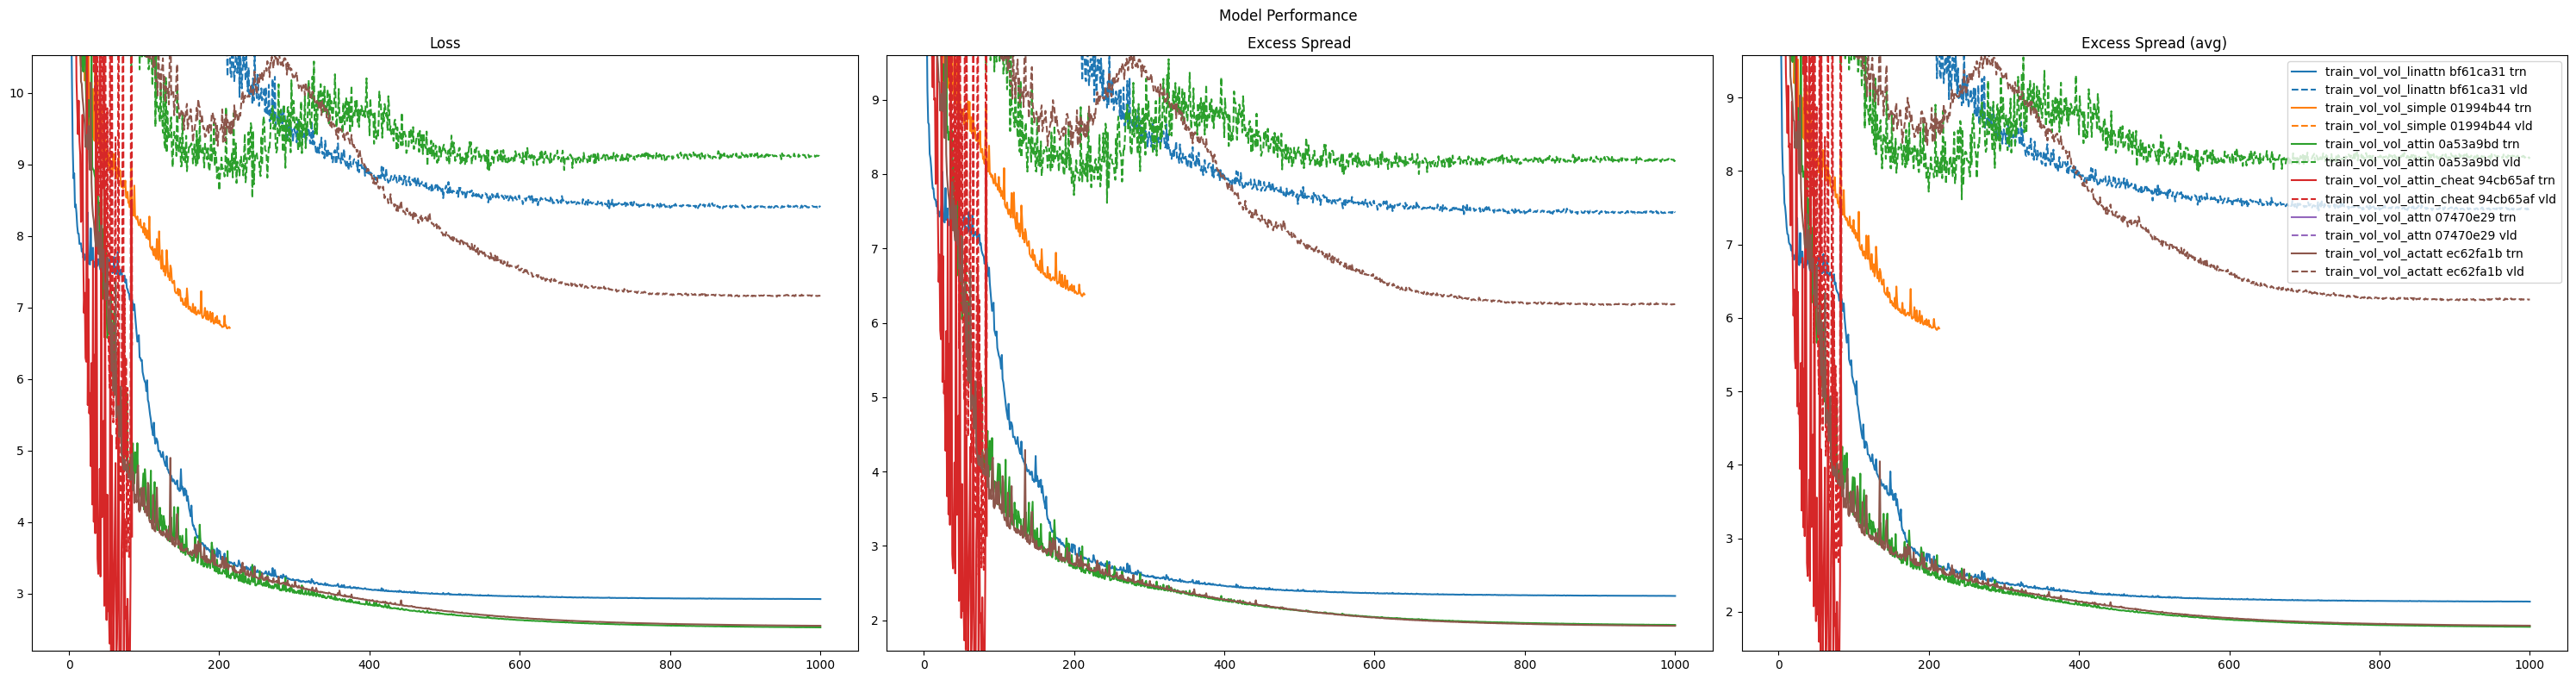

In [ ]:
from cdxcore.util import fmt_list
from cdxcore.pretty import PrettyObject
from cdxcore.dynaplot import figure, quantile_m_o_m, m_o_m, colors_tableau
from polars import time
from prettytable import PrettyTable
import time
import matplotlib.pyplot as plt

def summarize_experiments():
    experiment_root = TrainConfig(experiment_group=experiment_group).get_experiment_directory( sampler.unique_data_id, None)
    experiments     = experiment_root.sub_dirs()
    print(f"Found {len(experiments)} experiments in {experiment_root.path}.")

    with figure("Model Performance", row_size=8, col_size=10, columns=3) as fig:
        ax_loss, ax_spread, ax_spread_avg = fig.add_subplots("Loss", "Excess Spread", "Excess Spread (avg)")
        store = fig.store()
        fig.render()

        while True:
            tbl = PrettyTable(align="l")
            tbl.field_names = ["Experiment", "what", 'loss', 'excess_weighted', 'excess_weighted_avg', 'excess_spread', 'excess_spread_avg', 'excess', 'excess_avg']
            store.clear()

            colors = colors_tableau()

            for exp in experiments:
                ffn  = experiment_root(exp).full_file_name("last")
                last = torch.load(ffn, map_location="cpu", weights_only=False)
                last.pop("model_state_dict", None)
                last.pop("optimizer_state_dict", None)
                last.pop("rndg_state_dict", None)

                #  table
                row = [exp, "trn"]
                for fld in tbl.field_names[2:]:
                    fdata = PrettyObject(last['track_val_trn'][fld])
                    row.append(f"{fdata.values[-1]:.4g}|{fdata.stds[-1]:.4g}|{fdata.epochs[-1]}")
                tbl.add_row(row)
                row = ['', "vld"]
                for fld in tbl.field_names[2:]:
                    fdata = PrettyObject(last['track_val_vld'][fld])
                    row.append(f"{fdata.values[-1]:.4g}|{fdata.stds[-1]:.4g}|{fdata.epochs[-1]}")
                tbl.add_row(row)

                # plot
                trn_loss              = last['track_val_trn']['loss']
                vld_loss              = last['track_val_vld']['loss']
                trn_excess_spread     = last['track_val_trn']['excess_spread']
                vld_excess_spread     = last['track_val_vld']['excess_spread']
                trn_excess_spread_avg = last['track_val_trn']['excess_spread_avg']
                vld_excess_spread_avg = last['track_val_vld']['excess_spread_avg']
                color = next(colors)

                store += ax_loss.plot(trn_loss['epochs'], trn_loss['values'], label=f"{exp} trn", color=color)  
                store += ax_loss.plot(vld_loss['epochs'], vld_loss['values'], "--", label=f"{exp} vld", color=color)
                store += ax_spread.plot(trn_excess_spread['epochs'], trn_excess_spread['values'], label=f"{exp} trn", color=color)
                store += ax_spread.plot(vld_excess_spread['epochs'], vld_excess_spread['values'], "--", label=f"{exp} vld", color=color)
                store += ax_spread_avg.plot(trn_excess_spread_avg['epochs'], trn_excess_spread_avg['values'], label=f"{exp} trn", color=color)
                store += ax_spread_avg.plot(vld_excess_spread_avg['epochs'], vld_excess_spread_avg['values'], "--", label=f"{exp} vld", color=color)

            ax_loss.set_ylim( quantile_m_o_m( trn_loss['values'], vld_loss['values'], lo=0., pos_floor = 0.001 ) )
            ax_spread.set_ylim( quantile_m_o_m( trn_excess_spread['values'], vld_excess_spread['values'], lo=0., pos_floor = 0.001 ) )
            ax_spread_avg.set_ylim( quantile_m_o_m( trn_excess_spread_avg['values'], vld_excess_spread_avg['values'], lo=0., pos_floor = 0.001 )   )
            #store += ax_spread.legend(loc="upper right")
            store += ax_spread_avg.legend(loc="upper right")
            fig.render()
            plt.show()

            for i in range(int(5/0.2)):
                time.sleep(0.2)




summarize_experiments()